# 🏃‍♂️ Health & Fitness Trends

**Company:** VitalityApp
**Role:** Health Data Scientist

## 🏢 Scenario

VitalityApp tracks daily user movement and body metrics. The marketing team wants to segment users into **“Active”** and **“Inactive”** categories to send personalized workout notifications and improve engagement.

---

## 🎯 Your Tasks

### 1️⃣ Daily Activity Analysis

* Calculate the **average daily steps** across all users.
* This provides a baseline activity benchmark.

---

### 2️⃣ Identify Power Users

* Filter users who walk:

```
Steps > 10,000 per day
```

* These users represent highly active individuals.

---

### 3️⃣ Step Distribution

* Create a **Histogram** of daily steps.

* Include:

  * Title
  * Axis labels
  * Grid (optional)

* Analyze how steps are distributed among users.

---

### 4️⃣ Body Metrics Relationship

* Create a **Scatter Plot** showing:

```
Weight vs. Height
```

* Include:

  * Clear chart title
  * Axis labels

* Observe any visible trends or clusters.

---

### 5️⃣ User Segmentation

* Create a new column called **`Active_User`** where:

```
Active_User = True  if Steps ≥ 8000  
Active_User = False if Steps < 8000
```

* This will segment users for marketing campaigns.

---

### 6️⃣ Activity Comparison

* Count how many users are:

  * ✅ Active
  * ❌ Inactive

* Summarize the proportion of each segment.

---

## 📌 Expected Outcome

By completing this analysis, you should be able to:

* Understand overall user activity levels
* Identify highly active users
* Segment users effectively for targeted campaigns
* Analyze body metric relationships
* Provide insights for personalized fitness engagement strategies


In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv("/content/health_fitness_dataset.csv")

# Calculate average daily steps across all users
average_daily_steps = df["Daily_Steps"].mean()

print(f"Average daily steps: {average_daily_steps:.1f}")
print(f"Rounded average daily steps: {average_daily_steps:.0f}")

Average daily steps: 10080.8
Rounded average daily steps: 10081


In [3]:
import pandas as pd

# Load the dataset
df = pd.read_csv("/content/health_fitness_dataset.csv")

# Filter highly active users: strictly more than 10,000 daily steps
power_users = df[df["Daily_Steps"] > 10000][["Person_ID", "Daily_Steps"]]

# Sort from highest to lowest step count
power_users = power_users.sort_values("Daily_Steps", ascending=False)

print(power_users)
print(f"\nNumber of power users: {len(power_users)}")
print(f"Average steps among power users: {power_users['Daily_Steps'].mean():.0f}")

    Person_ID  Daily_Steps
3        3004        14567
8        3009        14371
17       3018        14312
16       3017        14304
1        3002        13914
10       3011        12777
4        3005        12458
6        3007        11603
12       3013        10973
18       3019        10681

Number of power users: 10
Average steps among power users: 12996


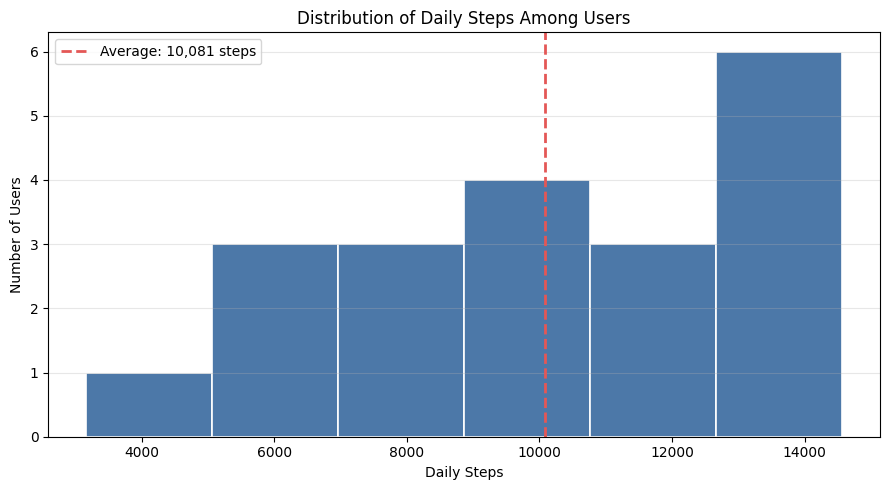

count       20.000000
mean     10080.800000
std       3463.788428
min       3162.000000
25%       7205.000000
50%      10229.000000
75%      13061.250000
max      14567.000000
Name: Daily_Steps, dtype: float64
Median: 10,229
Standard deviation: 3,464


In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("/content/health_fitness_dataset.csv")

# Keep valid daily-step values
daily_steps = df["Daily_Steps"].dropna()

# Create histogram
plt.figure(figsize=(9, 5))
plt.hist(
    daily_steps,
    bins=6,
    color="#4C78A8",
    edgecolor="white",
    linewidth=1.2
)

# Add average reference line
average_steps = daily_steps.mean()
plt.axvline(
    average_steps,
    color="#E45756",
    linestyle="--",
    linewidth=2,
    label=f"Average: {average_steps:,.0f} steps"
)

plt.title("Distribution of Daily Steps Among Users")
plt.xlabel("Daily Steps")
plt.ylabel("Number of Users")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Summary statistics
print(daily_steps.describe())
print(f"Median: {daily_steps.median():,.0f}")
print(f"Standard deviation: {daily_steps.std():,.0f}")

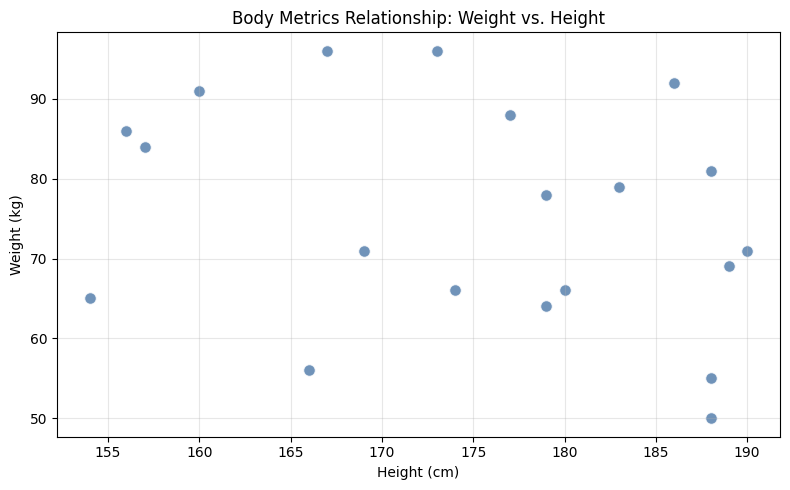

Height–weight correlation: -0.281


In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("/content/health_fitness_dataset.csv")

# Keep valid height and weight values
body_metrics = df[["Height_cm", "Weight_kg"]].dropna()

# Create scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(
    body_metrics["Height_cm"],
    body_metrics["Weight_kg"],
    color="#4C78A8",
    s=70,
    alpha=0.8,
    edgecolor="white",
    linewidth=0.8
)

# Title and axis labels
plt.title("Body Metrics Relationship: Weight vs. Height")
plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")

# Improve readability
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Optional: quantify the linear relationship
correlation = body_metrics["Height_cm"].corr(body_metrics["Weight_kg"])
print(f"Height–weight correlation: {correlation:.3f}")

In [14]:
import pandas as pd

# Load dataset
df = pd.read_csv("health_fitness_dataset.csv")

# Create marketing segment
df["Active_User"] = df["Daily_Steps"] >= 8000

# Optional: review segment counts
print(df["Active_User"].value_counts())
print(df[["Person_ID", "Daily_Steps", "Active_User"]].head())

Active_User
True     14
False     6
Name: count, dtype: int64
   Person_ID  Daily_Steps  Active_User
0       3001         9777         True
1       3002        13914         True
2       3003         5935        False
3       3004        14567         True
4       3005        12458         True


In [16]:
import pandas as pd

# Load the dataset from the correct CSV path
df = pd.read_csv("/content/health_fitness_dataset.csv")

# Define activity segments:
# Active: 8,000 or more daily steps
# Inactive: fewer than 8,000 daily steps
df["Activity_Segment"] = df["Daily_Steps"].apply(
    lambda steps: "Active" if steps >= 8000 else "Inactive"
)

# Count users in each segment
segment_counts = (
    df["Activity_Segment"]
    .value_counts()
    .reindex(["Active", "Inactive"])
    .rename_axis("Segment")
    .reset_index(name="User_Count")
)

# Calculate each segment's share of users
segment_counts["Proportion_Pct"] = (
    segment_counts["User_Count"] / len(df) * 100
).round(1)

print(segment_counts)

# Identify highly active users using a 10,000-step threshold
power_users = df[df["Daily_Steps"] > 10000].copy()
print(f"\nHighly active users (>10,000 steps): {len(power_users)} of {len(df)}")
print(power_users[["Person_ID", "Daily_Steps", "Activity_Segment"]])

    Segment  User_Count  Proportion_Pct
0    Active          14            70.0
1  Inactive           6            30.0

Highly active users (>10,000 steps): 10 of 20
    Person_ID  Daily_Steps Activity_Segment
1        3002        13914           Active
3        3004        14567           Active
4        3005        12458           Active
6        3007        11603           Active
8        3009        14371           Active
10       3011        12777           Active
12       3013        10973           Active
16       3017        14304           Active
17       3018        14312           Active
18       3019        10681           Active
